# AgroStake — Grapevine Disease Classifier
---
### 1. Imports

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import os
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset, Dataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import recall_score, confusion_matrix, classification_report
import numpy as np
from tqdm.auto import tqdm
import torch.nn.functional as F
from torchcam.methods import GradCAM
import random
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import sys

# Compatibility shim for old torchvision hub builds
if not hasattr(torch, '_six'):
    from unittest.mock import MagicMock
    mock = MagicMock()
    mock.string_classes = (str, bytes)
    torch._six = mock
    sys.modules['torch._six'] = mock

### 2. Device

In [2]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using: {device}')

Using: cuda


### 3. Load MobileNetV2 Backbone

In [3]:
model = torch.hub.load('pytorch/vision:v0.10.0', 'mobilenet_v2', pretrained=True)
model = model.to(device)
model.eval()

Using cache found in C:\Users\xared/.cache\torch\hub\pytorch_vision_v0.10.0
c:\Users\xared\AppData\Local\Programs\Python\Python311\Lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
c:\Users\xared\AppData\Local\Programs\Python\Python311\Lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=MobileNet_V2_Weights.IMAGENET1K_V1`. You can also use `weights=MobileNet_V2_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


MobileNetV2(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU6(inplace=True)
    )
    (1): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
          (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (2): ReLU6(inplace=True)
        )
        (1): Conv2d(32, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
    )
    (2): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(16, 96, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (1): BatchNorm2d(96, eps=

### 4. Dataset & Transforms

Two separate transforms:
- **`train_transform`** — aggressive augmentation to prevent background bias
- **`val_transform`** — clean resize + normalize only (never augment evaluation data)

`TransformSubset` wrapper ensures the val split gets `val_transform` even though it shares the same underlying `ImageFolder` as train.

In [4]:
# ── Transforms ──────────────────────────────────────────────────────────
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.6, 1.0)),  # prevents background shortcuts
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3, hue=0.1),
    transforms.RandomGrayscale(p=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# ── Custom wrapper: applies a chosen transform to a Subset ───────────────
class TransformSubset(Dataset):
    def __init__(self, subset, transform):
        self.subset = subset
        self.transform = transform

    def __len__(self):
        return len(self.subset)

    def __getitem__(self, idx):
        img_path, label = self.subset.dataset.samples[self.subset.indices[idx]]
        img = Image.open(img_path).convert('RGB')
        return self.transform(img), label

# ── Load raw ImageFolder (no transform — TransformSubset handles it) ─────
DATA_ROOT = '../0_data/augmented-dataset/'

full_train_raw = datasets.ImageFolder(root=os.path.join(DATA_ROOT, 'train'))

# ── Stratified 90/10 train/val split ────────────────────────────────────
indices = list(range(len(full_train_raw)))
train_idx, val_idx = train_test_split(
    indices, test_size=0.1, stratify=full_train_raw.targets, random_state=42
)

train_dataset = TransformSubset(Subset(full_train_raw, train_idx), train_transform)
val_dataset   = TransformSubset(Subset(full_train_raw, val_idx),   val_transform)
test_dataset  = datasets.ImageFolder(root=os.path.join(DATA_ROOT, 'test'), transform=val_transform)

# ── DataLoaders ──────────────────────────────────────────────────────────
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True,  num_workers=0)
val_loader   = DataLoader(val_dataset,   batch_size=32, shuffle=False, num_workers=0)
test_loader  = DataLoader(test_dataset,  batch_size=32, shuffle=False, num_workers=0)

CLASS_NAMES = full_train_raw.classes
print(f'Classes:  {CLASS_NAMES}')
print(f'Train: {len(train_dataset)} | Val: {len(val_dataset)} | Test: {len(test_dataset)}')

Classes:  ['Black Rot', 'ESCA', 'Healthy', 'Leaf Blight']
Train: 12999 | Val: 1445 | Test: 3610


### 5. Sanity Check — Batch Shape

In [6]:
images, labels = next(iter(train_loader))
print(f'Image batch: {images.shape}')  # [32, 3, 224, 224]
print(f'Label batch: {labels.shape}')  # [32]

Image batch: torch.Size([32, 3, 224, 224])
Label batch: torch.Size([32])


### 6. Class Distribution & Loss

The dataset is well-balanced (~3000 per class), so **no class weights are used**. Plain `CrossEntropyLoss` is sufficient.

In [5]:
from collections import Counter

label_counts = Counter([full_train_raw.targets[i] for i in train_idx])
class_counts = [label_counts[i] for i in range(len(CLASS_NAMES))]
print(dict(zip(CLASS_NAMES, class_counts)))

criterion = nn.CrossEntropyLoss()  # balanced dataset — no weights needed
print('Loss: CrossEntropyLoss (unweighted)')

{'Black Rot': 3398, 'ESCA': 3456, 'Healthy': 3046, 'Leaf Blight': 3099}
Loss: CrossEntropyLoss (unweighted)


### 7. Replace Classifier Head

In [6]:
# Swap ImageNet 1000-class head for a 4-class head
model.classifier[1] = nn.Linear(model.last_channel, 4)
model = model.to(device)
model.train()
print('Classifier updated for 4 classes.')

Classifier updated for 4 classes.


### 8. Visualize a Training Batch

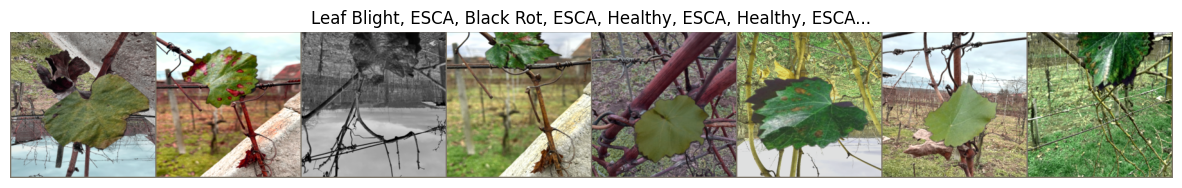

In [9]:
def imshow(inp, title=None):
    inp = inp.numpy().transpose((1, 2, 0))
    mean = np.array([0.485, 0.456, 0.406])
    std  = np.array([0.229, 0.224, 0.225])
    inp  = np.clip(std * inp + mean, 0, 1)
    plt.figure(figsize=(15, 10))
    plt.imshow(inp)
    if title:
        plt.title(', '.join(title[:8]) + '...')
    plt.axis('off')
    plt.show()

inputs, labels = next(iter(train_loader))
out = torchvision.utils.make_grid(inputs[:8])
imshow(out, title=[CLASS_NAMES[x] for x in labels[:8]])

### 9. Training & Evaluation Functions

In [7]:
def train_one_epoch(model, dataloader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0
    all_preds, all_labels = [], []
    pbar = tqdm(dataloader, desc='Training', leave=False)
    for i, (inputs, labels) in enumerate(dataloader):
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * inputs.size(0)
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())
        if (i + 1) % 10 == 0:
            pbar.update(10)
            pbar.set_postfix_str(
                f'loss={loss.item():.4f} | recall={recall_score(all_labels, all_preds, average="macro"):.4f}'
            )
    return running_loss / len(dataloader.dataset), all_preds, all_labels


def evaluate(model, dataloader, criterion, device):
    model.eval()
    running_loss = 0.0
    all_preds, all_labels = [], []
    with torch.no_grad():
        for inputs, labels in tqdm(dataloader, desc='Evaluating', leave=False):
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            running_loss += loss.item() * inputs.size(0)
            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
    recall = recall_score(all_labels, all_preds, average='macro')
    return running_loss / len(dataloader.dataset), recall


def plot_confusion(labels, preds, title='Confusion Matrix'):
    cm = confusion_matrix(labels, preds)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Greens',
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    plt.title(title)
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.show()
    print(classification_report(labels, preds, target_names=CLASS_NAMES))

### 10. Phase 1 — Head Training (Backbone Frozen)

Freeze the entire MobileNetV2 backbone and train only the new 4-class head. The backbone already contains strong ImageNet features — training the head first lets it stabilize before the full fine-tune in Phase 2.

In [11]:
# Freeze backbone
for param in model.features.parameters():
    param.requires_grad = False

num_epochs_p1 = 20
optimizer_p1 = torch.optim.AdamW(model.classifier.parameters(), lr=1e-3)
scheduler_p1 = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer_p1, T_max=20, eta_min=1e-6
)

best_recall_p1 = 0.0
for epoch in range(num_epochs_p1):
    train_loss, _, _ = train_one_epoch(model, train_loader, criterion, optimizer_p1, device)
    val_loss, val_recall = evaluate(model, val_loader, criterion, device)
    print(f'Epoch {epoch+1}/{num_epochs_p1} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Val Recall: {val_recall:.4f}')
    if val_recall > best_recall_p1:
        best_recall_p1 = val_recall
        torch.save(model.state_dict(), '../4_models/agroStake_p1.pth')
        print(f'  -> Best saved: {best_recall_p1:.4f}')
    scheduler_p1.step()

Training:   0%|          | 0/407 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/46 [00:00<?, ?it/s]

Epoch 1/20 | Train Loss: 0.7429 | Val Loss: 0.5036 | Val Recall: 0.8154
  -> Best saved: 0.8154


Training:   0%|          | 0/407 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/46 [00:00<?, ?it/s]

...

Evaluating:   0%|          | 0/46 [00:00<?, ?it/s]

Epoch 19/20 | Train Loss: 0.4517 | Val Loss: 0.3704 | Val Recall: 0.8579


Training:   0%|          | 0/407 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/46 [00:00<?, ?it/s]

Epoch 20/20 | Train Loss: 0.4645 | Val Loss: 0.3642 | Val Recall: 0.8535


### 11. Phase 1 — Validation Evaluation

In [8]:
# Reload cleanly to clear any hook residue before evaluation
model_p1 = torch.hub.load('pytorch/vision:v0.10.0', 'mobilenet_v2', pretrained=False)
model_p1.classifier[1] = nn.Linear(model_p1.last_channel, 4)
model_p1.load_state_dict(torch.load('../4_models/agroStake_p1.pth', map_location=device))
model_p1 = model_p1.to(device)
model_p1.eval()

p1_preds, p1_labels = [], []
with torch.no_grad():
    for inputs, labels in val_loader:
        inputs = inputs.to(device)
        _, preds = torch.max(model_p1(inputs), 1)
        p1_preds.extend(preds.cpu().numpy())
        p1_labels.extend(labels.cpu().numpy())

plot_confusion(p1_labels, p1_preds, title='Phase 1 — Val Confusion Matrix')

Using cache found in C:\Users\xared/.cache\torch\hub\pytorch_vision_v0.10.0
c:\Users\xared\AppData\Local\Programs\Python\Python311\Lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
c:\Users\xared\AppData\Local\Programs\Python\Python311\Lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)
C:\Users\xared\AppData\Local\Temp\ipykernel_12656\1992618329.py:4: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/py

KeyboardInterrupt: 

### 12. Error Analysis — Probability Spread

For each misclassification, print the softmax probability spread:
- Spread close to 50/50 → genuine ambiguity, model is uncertain (acceptable)
- One class at 0.98+ → overconfident wrong answer (problematic)

In [9]:
model_p1.eval()
with torch.no_grad():
    for inputs, labels in val_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model_p1(inputs)
        probs = F.softmax(outputs, dim=1)
        _, preds = torch.max(outputs, 1)
        mask = preds != labels
        for i in range(len(mask)):
            if mask[i]:
                print(f'Actual: {CLASS_NAMES[labels[i]]}')
                print(f'Probs:  {dict(zip(CLASS_NAMES, [round(float(p), 3) for p in probs[i]]))}')
                print('-' * 40)

Actual: Leaf Blight
Probs:  {'Black Rot': 0.569, 'ESCA': 0.011, 'Healthy': 0.0, 'Leaf Blight': 0.42}
----------------------------------------
Actual: ESCA
Probs:  {'Black Rot': 0.456, 'ESCA': 0.261, 'Healthy': 0.255, 'Leaf Blight': 0.028}
----------------------------------------
Actual: ESCA
Probs:  {'Black Rot': 0.526, 'ESCA': 0.448, 'Healthy': 0.018, 'Leaf Blight': 0.008}
----------------------------------------
Actual: Leaf Blight
Probs:  {'Black Rot': 0.301, 'ESCA': 0.302, 'Healthy': 0.346, 'Leaf Blight': 0.051}
----------------------------------------
Actual: ESCA
Probs:  {'Black Rot': 0.263, 'ESCA': 0.148, 'Healthy': 0.001, 'Leaf Blight': 0.588}
----------------------------------------
Actual: Black Rot
Probs:  {'Black Rot': 0.344, 'ESCA': 0.647, 'Healthy': 0.005, 'Leaf Blight': 0.005}
----------------------------------------
Actual: ESCA
Probs:  {'Black Rot': 0.592, 'ESCA': 0.292, 'Healthy': 0.106, 'Leaf Blight': 0.01}
----------------------------------------
Actual: ESCA
Probs:

In [5]:
import cv2
import numpy as np

def resize_to_96(img_path, output_path):
    img = cv2.imread(img_path)

    if img is None:
        raise ValueError("Image not found or path is incorrect")

    resized = cv2.resize(img, (96, 96), interpolation=cv2.INTER_AREA)

    # Proper kernel (NumPy array, float32)
    kernel = np.array([[0, -1, 0],
                       [-1, 5, -1],
                       [0, -1, 0]], dtype=np.float32)

    sharpened = cv2.filter2D(resized, -1, kernel)

    cv2.imwrite(output_path, sharpened)



# Example usage
resize_to_96(
    "C:\\Users\\xared\\Documents\\30_PROJECTS\\31_Grapevine_License\\0_data\\augmented-dataset\\test\\ESCA\\fc7a8460-2637-47fe-9691-1db817f39da9___FAM_B.Msls 1016_aug2.png",
    "C:\\Users\\xared\\Documents\\30_PROJECTS\\31_Grapevine_License\\output.jpg"
)


In [9]:
import cv2
import numpy as np

def resize_to_96_gray(img_path, output_path):
    img = cv2.imread(img_path)

    if img is None:
        raise ValueError("Image not found or path is incorrect")

    # Resize with best downscaling method
    resized = cv2.resize(img, (96, 96), interpolation=cv2.INTER_AREA)

    # Convert to grayscale
    gray = cv2.cvtColor(resized, cv2.COLOR_BGR2GRAY)
    gray = cv2.equalizeHist(gray)  # improves contrast
    # Optional: mild sharpening (safer for grayscale datasets)
    kernel = np.array([[0, -1, 0],
                       [-1, 5, -1],
                       [0, -1, 0]], dtype=np.float32)

    sharpened = cv2.filter2D(gray, -1, kernel)

    cv2.imwrite(output_path, sharpened)


resize_to_96_gray(
    r"C:\Users\xared\Documents\30_PROJECTS\31_Grapevine_License\0_data\augmented-dataset\test\ESCA\fc7a8460-2637-47fe-9691-1db817f39da9___FAM_B.Msls 1016_aug2.png",
    r"C:\Users\xared\Documents\30_PROJECTS\31_Grapevine_License\output_gray_im.jpg"
)

In [8]:
import cv2
import numpy as np

def resize_to_96_gray(img_path, output_path):
    img = cv2.imread(img_path)

    if img is None:
        raise ValueError("Image not found or path is incorrect")

    # Resize with best downscaling method
    resized = cv2.resize(img, (96, 96), interpolation=cv2.INTER_AREA)

    # Convert to grayscale
    gray = cv2.cvtColor(resized, cv2.COLOR_BGR2GRAY)

    # Optional: mild sharpening (safer for grayscale datasets)
    kernel = np.array([[0, -1, 0],
                       [-1, 5, -1],
                       [0, -1, 0]], dtype=np.float32)

    sharpened = cv2.filter2D(gray, -1, kernel)

    cv2.imwrite(output_path, sharpened)


resize_to_96_gray(
    r"C:\Users\xared\Documents\30_PROJECTS\31_Grapevine_License\0_data\augmented-dataset\test\ESCA\fc7a8460-2637-47fe-9691-1db817f39da9___FAM_B.Msls 1016_aug2.png",
    r"C:\Users\xared\Documents\30_PROJECTS\31_Grapevine_License\output_gray3.jpg"
)

In [3]:
!pip install opencv-python 

   ---------------------------------------- 0.0/40.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/40.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/40.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/40.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/40.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/40.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/40.2 MB ? eta -:--:--
   ---------------------------------------- 0.3/40.2 MB ? eta -:--:--
   ---------------------------------------- 0.3/40.2 MB ? eta -:--:--
   ---------------------------------------- 0.3/40.2 MB ? eta -:--:--
   ---------------------------------------- 0.3/40.2 MB ? eta -:--:--
   ---------------------------------------- 0.3/40.2 MB ? eta -:--:--
   ---------------------------------------- 0.3/40.2 MB ? eta -:--:--
    --------------------------------------- 0.5/40.2 MB 229.9 kB/s eta 0:02:53
    -------

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
torchcam 0.4.1 requires numpy<2.0.0,>=1.17.2, but you have numpy 2.4.4 which is incompatible.


In [22]:

from torchinfo import summary

# You must provide the input_size so the library can do a dry run
summary(model, input_size=(8, 3, 96, 96))


Layer (type:depth-idx)                             Output Shape              Param #
MobileNetV2                                        [8, 4]                    --
├─Sequential: 1-1                                  [8, 1280, 3, 3]           --
│    └─Conv2dNormActivation: 2-1                   [8, 32, 48, 48]           --
│    │    └─Conv2d: 3-1                            [8, 32, 48, 48]           864
│    │    └─BatchNorm2d: 3-2                       [8, 32, 48, 48]           64
│    │    └─ReLU6: 3-3                             [8, 32, 48, 48]           --
│    └─InvertedResidual: 2-2                       [8, 16, 48, 48]           --
│    │    └─Sequential: 3-4                        [8, 16, 48, 48]           896
│    └─InvertedResidual: 2-3                       [8, 24, 24, 24]           --
│    │    └─Sequential: 3-5                        [8, 24, 24, 24]           5,136
│    └─InvertedResidual: 2-4                       [8, 24, 24, 24]           --
│    │    └─Sequential: 3-6   

### 13. Phase 2 — Full Fine-Tuning (Backbone Unfrozen)

Unfreeze the entire network and train with a much smaller learning rate. The backbone now adapts its ImageNet features toward grape disease patterns.

**Key settings:**
- AdamW with `weight_decay=1e-4` for regularization
- LR drops from `1e-5` to `1e-7` via CosineAnnealing
- 10 epochs to resolve the remaining Black Rot / ESCA confusion

In [10]:
import gc
torch.cuda.empty_cache()
gc.collect()

3851

In [11]:
train_loader_p2 = DataLoader(train_dataset, batch_size=16, shuffle=True,  num_workers=0)
val_loader_p2   = DataLoader(val_dataset,   batch_size=16, shuffle=False, num_workers=0)

In [12]:
import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

In [13]:
# Clean reload from Phase 1 checkpoint
model = torch.hub.load('pytorch/vision:v0.10.0', 'mobilenet_v2', pretrained=False)
model.classifier[1] = nn.Linear(model.last_channel, 4)
model.load_state_dict(torch.load('../4_models/agroStake_p1.pth', map_location=device))
model = model.to(device)

# Unfreeze everything
for param in model.parameters():
    param.requires_grad = True

optimizer_p2 = torch.optim.AdamW(model.parameters(), lr=1e-5, weight_decay=1e-4)
num_epochs_p2 = 10
scheduler_p2  = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer_p2, T_max=num_epochs_p2, eta_min=1e-7
)

best_recall_p2 = 0.0
for epoch in range(num_epochs_p2):
    train_loss, _, _ = train_one_epoch(model, train_loader, criterion, optimizer_p2, device)
    val_loss, val_recall = evaluate(model, val_loader, criterion, device)
    print(f'Phase 2 - Epoch {epoch+1}/{num_epochs_p2} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Val Recall: {val_recall:.4f}')
    if val_recall > best_recall_p2:
        best_recall_p2 = val_recall
        torch.save(model.state_dict(), '../4_models/agroStake_p2.pth')
        print(f'  -> Best saved: {best_recall_p2:.4f}')
    scheduler_p2.step()

Using cache found in C:\Users\xared/.cache\torch\hub\pytorch_vision_v0.10.0
C:\Users\xared\AppData\Local\Temp\ipykernel_12656\547444773.py:4: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimen

Training:   0%|          | 0/407 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/46 [00:00<?, ?it/s]

Phase 2 - Epoch 1/10 | Train Loss: 0.2774 | Val Loss: 0.1575 | Val Recall: 0.9334
  -> Best saved: 0.9334


Training:   0%|          | 0/407 [00:00<?, ?it/s]

...

Evaluating:   0%|          | 0/46 [00:00<?, ?it/s]

Phase 2 - Epoch 9/10 | Train Loss: 0.0789 | Val Loss: 0.0605 | Val Recall: 0.9759


Training:   0%|          | 0/407 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/46 [00:00<?, ?it/s]

Phase 2 - Epoch 10/10 | Train Loss: 0.0826 | Val Loss: 0.0601 | Val Recall: 0.9781
  -> Best saved: 0.9781


### 14. Phase 2 — Validation Evaluation

Using cache found in C:\Users\xared/.cache\torch\hub\pytorch_vision_v0.10.0
c:\Users\xared\AppData\Local\Programs\Python\Python311\Lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
c:\Users\xared\AppData\Local\Programs\Python\Python311\Lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)
C:\Users\xared\AppData\Local\Temp\ipykernel_12656\1678754909.py:3: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/py

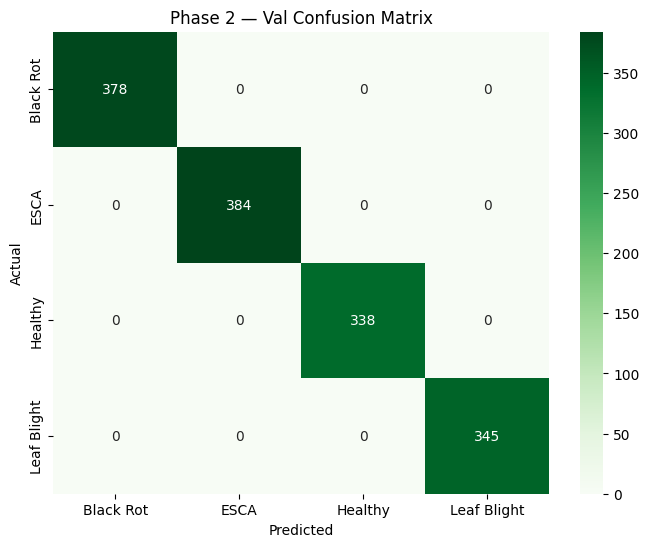

              precision    recall  f1-score   support

   Black Rot       1.00      1.00      1.00       378
        ESCA       1.00      1.00      1.00       384
     Healthy       1.00      1.00      1.00       338
 Leaf Blight       1.00      1.00      1.00       345

    accuracy                           1.00      1445
   macro avg       1.00      1.00      1.00      1445
weighted avg       1.00      1.00      1.00      1445



In [14]:
model_p2 = torch.hub.load('pytorch/vision:v0.10.0', 'mobilenet_v2', pretrained=False)
model_p2.classifier[1] = nn.Linear(model_p2.last_channel, 4)
model_p2.load_state_dict(torch.load('../4_models/agroStake_p2.pth', map_location=device))
model_p2 = model_p2.to(device)
model_p2.eval()

p2_preds, p2_labels = [], []
with torch.no_grad():
    for inputs, labels in val_loader:
        inputs = inputs.to(device)
        _, preds = torch.max(model_p2(inputs), 1)
        p2_preds.extend(preds.cpu().numpy())
        p2_labels.extend(labels.cpu().numpy())

plot_confusion(p2_labels, p2_labels, title='Phase 2 — Val Confusion Matrix')

### 15. Final Evaluation — Test Set

The test set has been completely untouched throughout training. These are the numbers reported in the thesis.

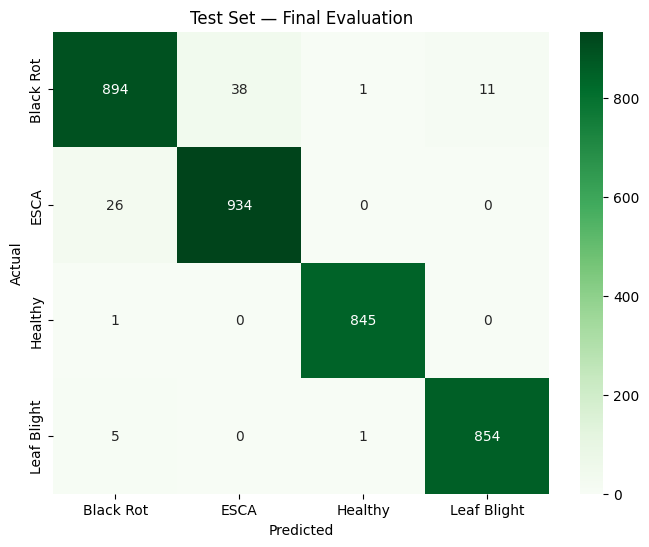

              precision    recall  f1-score   support

   Black Rot       0.97      0.95      0.96       944
        ESCA       0.96      0.97      0.97       960
     Healthy       1.00      1.00      1.00       846
 Leaf Blight       0.99      0.99      0.99       860

    accuracy                           0.98      3610
   macro avg       0.98      0.98      0.98      3610
weighted avg       0.98      0.98      0.98      3610



In [15]:
test_preds, test_labels = [], []
with torch.no_grad():
    for inputs, labels in test_loader:
        inputs = inputs.to(device)
        _, preds = torch.max(model_p2(inputs), 1)
        test_preds.extend(preds.cpu().numpy())
        test_labels.extend(labels.cpu().numpy())

plot_confusion(test_labels, test_preds, title='Test Set — Final Evaluation')

### 16. GradCAM — Visual Explainability

Visualizes which image regions the model attends to when predicting. Red = high attention, blue = low attention.

> **Run this cell last.** GradCAM registers forward hooks that conflict with `torch.no_grad()`. Always use a freshly loaded model object for GradCAM.

Using cache found in C:\Users\xared/.cache\torch\hub\pytorch_vision_v0.10.0
C:\Users\xared\AppData\Local\Temp\ipykernel_12656\951285360.py:48: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experime

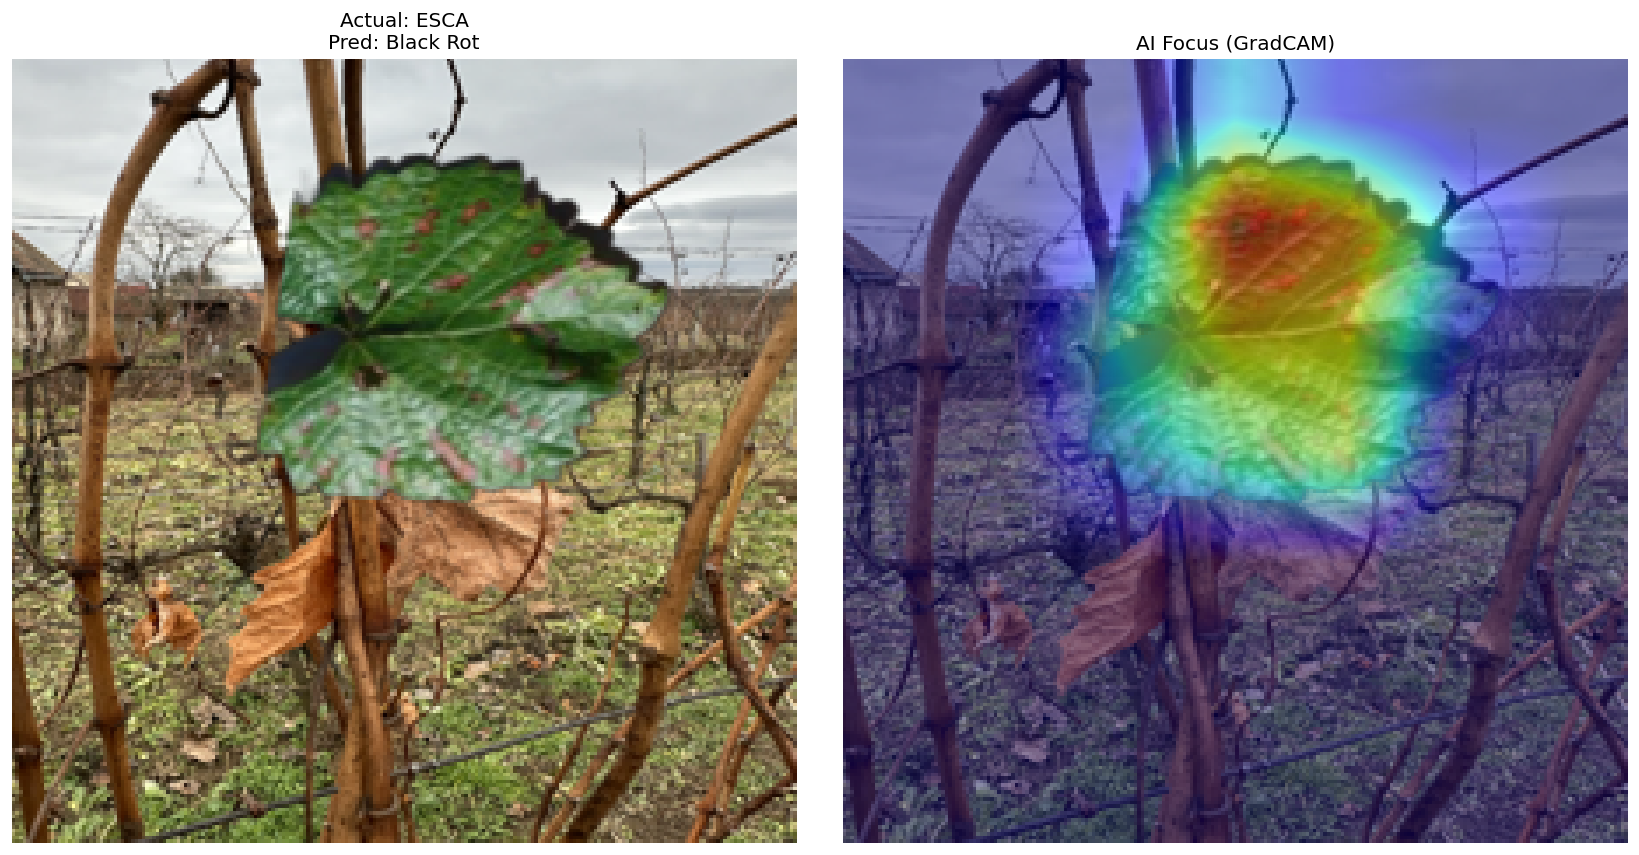

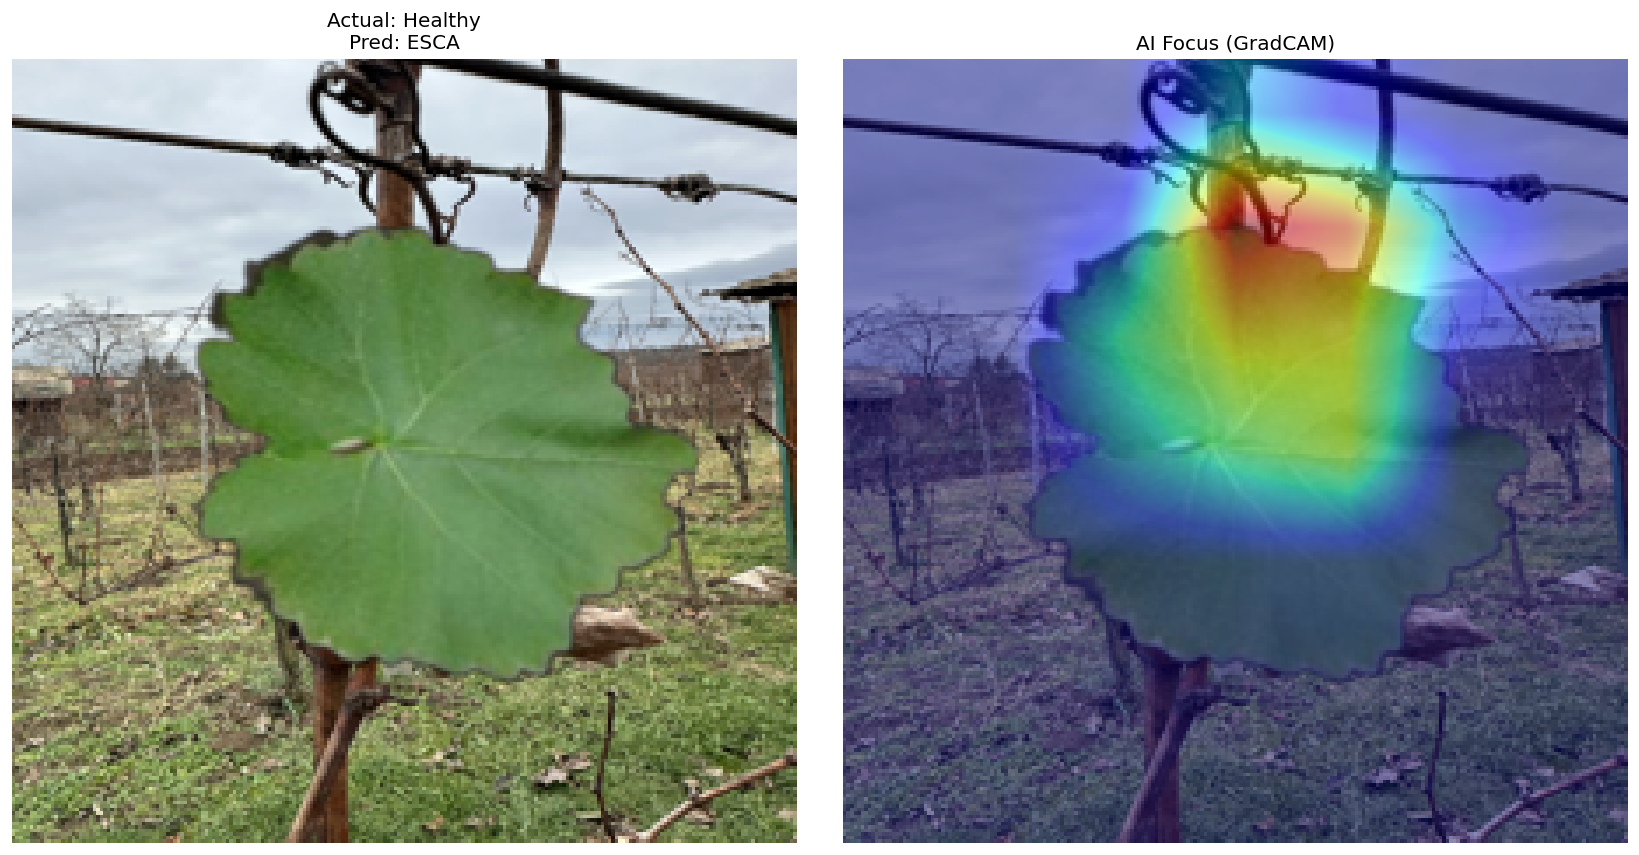

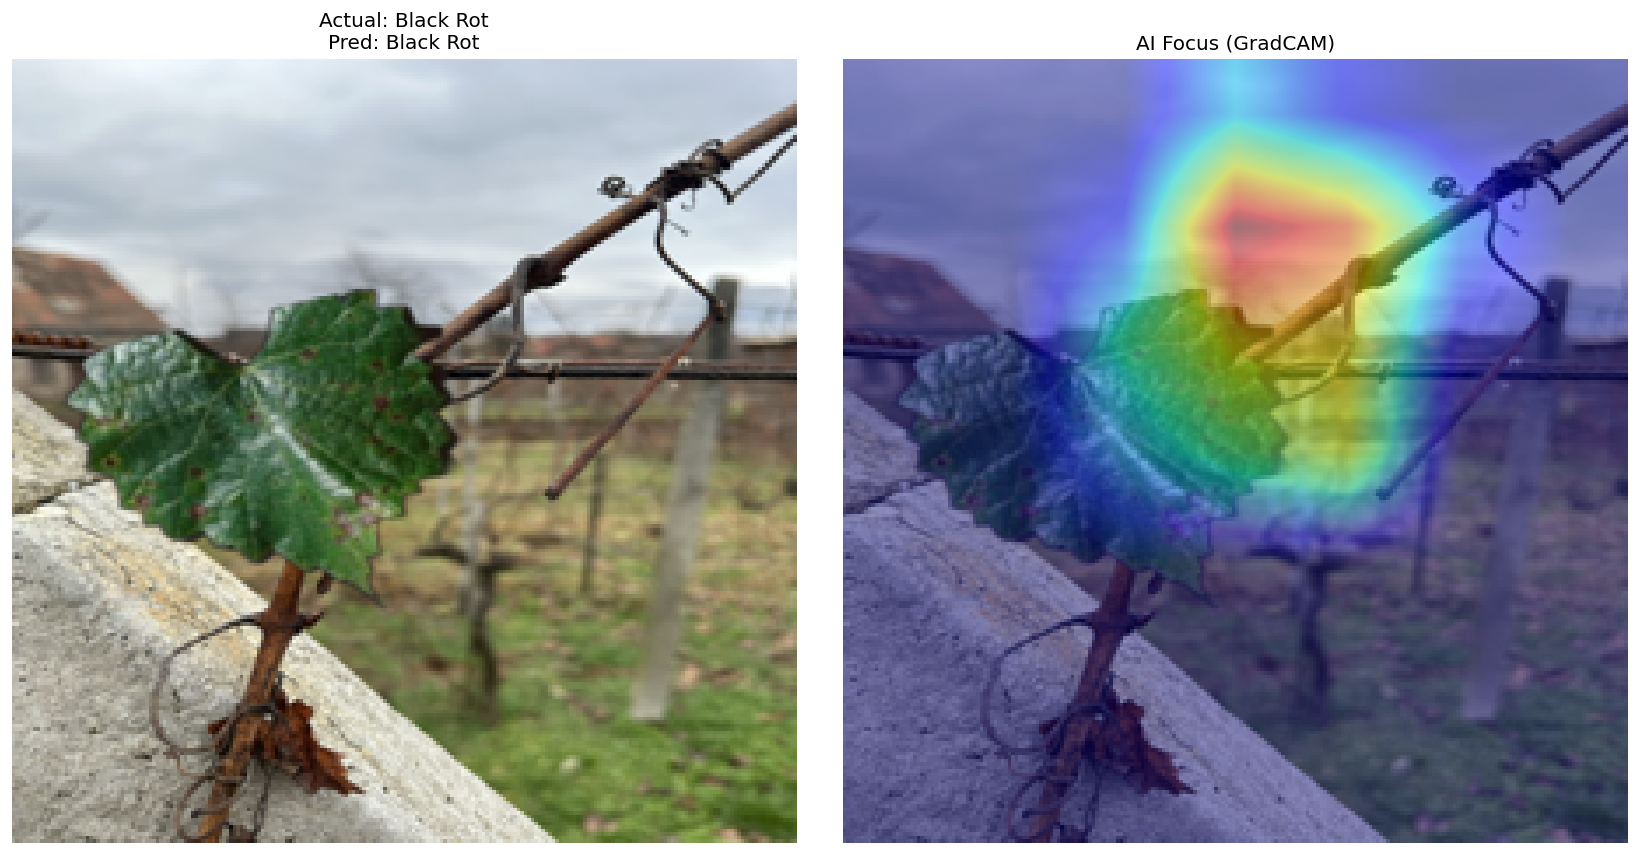

In [43]:
def visualize_gradcam(model, dataset_folder, device, num_samples=3):
    """
    dataset_folder: raw ImageFolder (val_transform applied internally)
    so GradCAM always sees the unaugmented image.
    """
    model.train()  # GradCAM needs gradients
    cam_extractor = GradCAM(model, target_layer='features')

    for _ in range(num_samples):
        idx = random.randint(0, len(dataset_folder) - 1)
        img_path, true_label = dataset_folder.samples[idx]
        img_pil = Image.open(img_path).convert('RGB')
        img_tensor = val_transform(img_pil).unsqueeze(0).to(device)

        for param in model.features.parameters():
            param.requires_grad = True

        out = model(img_tensor)
        pred_idx = out.squeeze(0).argmax().item()
        activation_map = cam_extractor(pred_idx, out)
        cam_extractor.remove_hooks()

        raw_heatmap = activation_map[0].squeeze(0).unsqueeze(0).unsqueeze(0)
        hi_res = F.interpolate(raw_heatmap, size=(224, 224), mode='bilinear', align_corners=False)
        hi_res = hi_res.squeeze().cpu().numpy()
        hi_res = (hi_res - hi_res.min()) / (hi_res.max() - hi_res.min() + 1e-8)

        raw_img = img_pil.resize((224, 224))
        fig, axes = plt.subplots(1, 2, figsize=(14, 7), dpi=120)
        axes[0].imshow(raw_img)
        axes[0].set_title(f'Actual: {CLASS_NAMES[true_label]}\nPred: {CLASS_NAMES[pred_idx]}', fontsize=12)
        axes[0].axis('off')
        axes[1].imshow(raw_img)
        axes[1].imshow(hi_res, cmap='jet', alpha=0.45, interpolation='bilinear')
        axes[1].set_title('AI Focus (GradCAM)', fontsize=12)
        axes[1].axis('off')
        plt.tight_layout()
        plt.show()

    model.eval()
    for param in model.features.parameters():
        param.requires_grad = False


# Load a clean model just for GradCAM
model_cam = torch.hub.load('pytorch/vision:v0.10.0', 'mobilenet_v2', pretrained=False)
model_cam.classifier[1] = nn.Linear(model_cam.last_channel, 4)
model_cam.load_state_dict(torch.load('../4_models/agroStake_p2.pth', map_location=device))
model_cam = model_cam.to(device)

test_folder = datasets.ImageFolder(root=os.path.join(DATA_ROOT, 'test'))
visualize_gradcam(model_cam, test_folder, device, num_samples=3)